In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

C:\Users\Eka\anaconda3\envs\cnn_pi\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
train_dir = "../dataset_custom_split/train"
val_dir = "../dataset_custom_split/val"
test_dir = "../dataset_custom_split/test"

img_height = 64
img_width = 64
batch_size = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size
)

print("Dataset custom berhasil dimuat")
print("Class:", train_dataset.class_names)

Found 905 files belonging to 2 classes.
Found 272 files belonging to 2 classes.
Found 269 files belonging to 2 classes.
Dataset custom berhasil dimuat
Class: ['awake', 'sleepy']


In [3]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(700).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

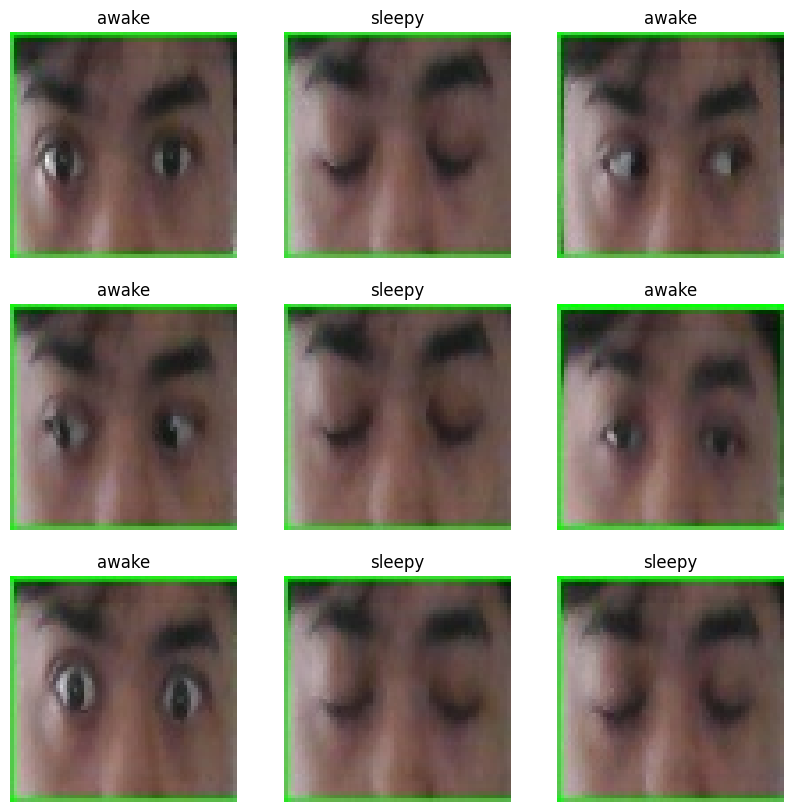

In [4]:
class_names = ['awake', 'sleepy']

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [5]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(factor=(-0.2, 0.2))
])

In [6]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(2, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │             258 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 683,458 (2.61 MB)

 Trainable params: 683,458 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20
)

Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.5757 - loss: 0.6626 - val_accuracy: 0.9779 - val_loss: 0.3762
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9293 - loss: 0.2125 - val_accuracy: 0.9118 - val_loss: 0.1839
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9558 - loss: 0.1399 - val_accuracy: 0.9816 - val_loss: 0.1043
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9669 - loss: 0.1350 - val_accuracy: 0.9559 - val_loss: 0.1064
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9812 - loss: 0.0691 - val_accuracy: 0.9963 - val_loss: 0.0138
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9834 - loss: 0.0572 - val_accuracy: 1.0000 - val_loss: 0.0140
Epoch 7/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9867 - loss: 0.0511 - val_accuracy: 1.0000 - val_loss: 0.0091
Epoch 8/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9856 - loss: 0.0509 - val_accuracy: 1.0000 - v

In [9]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Accuracy :", test_accuracy)
print("Test Loss :", test_loss)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9926 - loss: 0.0146
Test Accuracy : 0.9925650358200073
Test Loss : 0.014601298607885838


In [10]:
model.save("../models/drowsiness_model_custom_v1.keras")

print("Model custom berhasil disimpan")

Model custom berhasil disimpan


In [14]:
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

print("Folder results siap:", RESULTS_DIR)

Folder results siap: ..\results


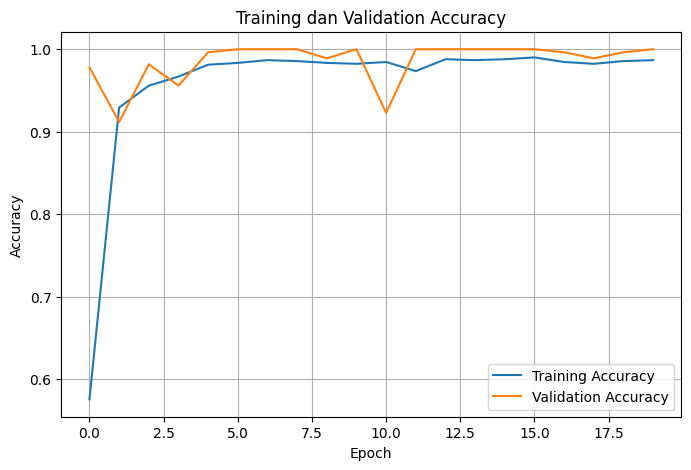

Grafik accuracy tersimpan di: ..\results\accuracy_plot_custom.png


In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training dan Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(RESULTS_DIR / "accuracy_plot_custom.png", dpi=300, bbox_inches="tight")
plt.show()

print("Grafik accuracy tersimpan di:", RESULTS_DIR / "accuracy_plot_custom.png")

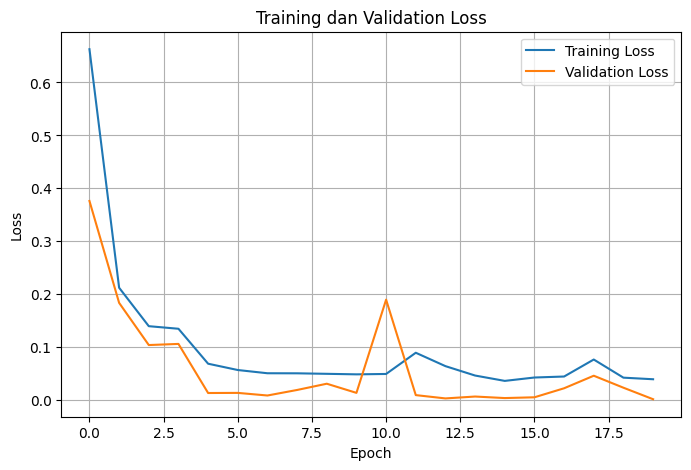

Grafik loss tersimpan di: ..\results\loss_plot_custom.png


In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training dan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(RESULTS_DIR / "loss_plot_custom.png", dpi=300, bbox_inches="tight")
plt.show()

print("Grafik loss tersimpan di:", RESULTS_DIR / "loss_plot_custom.png")

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       awake     1.0000    0.9851    0.9925       134
      sleepy     0.9854    1.0000    0.9926       135

    accuracy                         0.9926       269
   macro avg     0.9927    0.9925    0.9926       269
weighted avg     0.9927    0.9926    0.9926       269



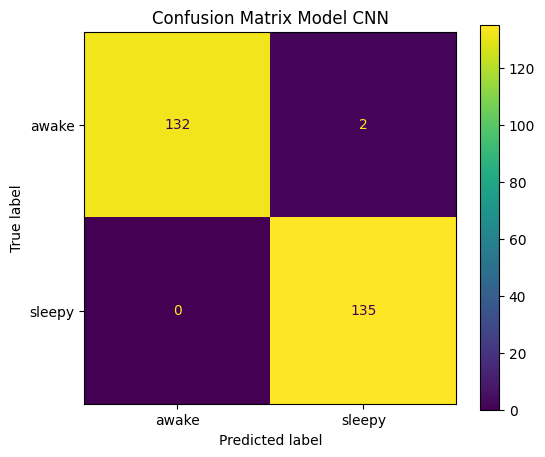

Confusion matrix tersimpan di: ..\results\confusion_matrix_custom.png
Classification report tersimpan di: ..\results\classification_report_custom.txt


In [17]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print("CLASSIFICATION REPORT")
print(report)

with open(RESULTS_DIR / "classification_report_custom.txt", "w") as f:
    f.write(report)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, values_format="d")
plt.title("Confusion Matrix Model CNN")

plt.savefig(RESULTS_DIR / "confusion_matrix_custom.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix tersimpan di:", RESULTS_DIR / "confusion_matrix_custom.png")
print("Classification report tersimpan di:", RESULTS_DIR / "classification_report_custom.txt")

In [18]:
final_train_acc = history.history["accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_acc = history.history["val_accuracy"][-1]
final_val_loss = history.history["val_loss"][-1]

summary_text = f"""
RINGKASAN HASIL PELATIHAN MODEL CNN

Training Accuracy   : {final_train_acc:.4f}
Training Loss       : {final_train_loss:.4f}
Validation Accuracy : {final_val_acc:.4f}
Validation Loss     : {final_val_loss:.4f}
Test Accuracy       : {test_accuracy:.4f}
Test Loss           : {test_loss:.4f}
Epoch               : 20
Batch Size          : {batch_size}
Input Size          : 64 x 64
Kelas               : {class_names}
Model               : drowsiness_model_custom.keras
"""

print(summary_text)

with open(RESULTS_DIR / "training_summary_custom.txt", "w") as f:
    f.write(summary_text)

print("Ringkasan training tersimpan di:", RESULTS_DIR / "training_summary_custom.txt")


RINGKASAN HASIL PELATIHAN MODEL CNN

Training Accuracy   : 0.9867
Training Loss       : 0.0397
Validation Accuracy : 1.0000
Validation Loss     : 0.0020
Test Accuracy       : 0.9926
Test Loss           : 0.0146
Epoch               : 20
Batch Size          : 32
Input Size          : 64 x 64
Kelas               : ['awake', 'sleepy']
Model               : drowsiness_model_custom.keras

Ringkasan training tersimpan di: ..\results\training_summary_custom.txt


In [17]:
from pathlib import Path

base_dir = Path("../dataset_custom_split")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    total_split = 0

    for cls in ["awake", "sleepy"]:
        folder = base_dir / split / cls
        count = len([
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])

        total_split += count
        print(f"{cls}: {count}")

    print(f"Total {split}: {total_split}")


TRAIN
awake: 450
sleepy: 455
Total train: 905

VAL
awake: 136
sleepy: 136
Total val: 272

TEST
awake: 134
sleepy: 135
Total test: 269


In [1]:
import tensorflow as tf
print(tf.__version__)

import keras
print(keras.__version__)

C:\Users\Eka\anaconda3\envs\cnn_pi\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


2.21.0
3.12.1


In [2]:
from tensorflow.keras import layers

print(hasattr(layers, "RandomBrightness"))

True


In [1]:
import cv2
print(cv2.__version__)

4.13.0


In [2]:
import tensorflow as tf
print(tf.__version__)

C:\Users\Eka\anaconda3\envs\cnn_pi\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


2.21.0
